DOWNLOAD DATASET FROM KAGGLE

In [25]:
from pathlib import Path
import zipfile
import urllib.request

def download_kaggle_dataset(url):
    tarball_path = Path("datasets/loan_approval_dataset.zip")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, tarball_path)
    with zipfile.ZipFile(tarball_path, 'r') as loan_approval_zip:
            loan_approval_zip.extractall(path="datasets")

download_kaggle_dataset("https://www.kaggle.com/api/v1/datasets/download/architsharma01/loan-approval-prediction-dataset")

IMPORT THE DATASET FILE

In [37]:
import pandas as pd
df = pd.read_csv('datasets/loan_approval_dataset.csv')

CLEAN THE DATA (`attribute and observations contains trailing whitespaces`)

In [38]:
# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

# Remove leading and trailing spaces from string values in the DataFrame
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

# Inspect null values in the DataFrame
print(df.isnull().sum())

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


INSPECT AND UNDERSTAND THE DATASET

In [39]:
# Dataset Shape
r, c = df.shape
print(f"The dataset has {c} attributes and {r} observations.")

# Dataset Information
df.info()

The dataset has 13 attributes and 4269 observations.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
m

UNDERSTAND THE VALUES RANGE

array([[<Axes: title={'center': 'loan_id'}>,
        <Axes: title={'center': 'no_of_dependents'}>,
        <Axes: title={'center': 'income_annum'}>],
       [<Axes: title={'center': 'loan_amount'}>,
        <Axes: title={'center': 'loan_term'}>,
        <Axes: title={'center': 'cibil_score'}>],
       [<Axes: title={'center': 'residential_assets_value'}>,
        <Axes: title={'center': 'commercial_assets_value'}>,
        <Axes: title={'center': 'luxury_assets_value'}>],
       [<Axes: title={'center': 'bank_asset_value'}>, <Axes: >, <Axes: >]],
      dtype=object)

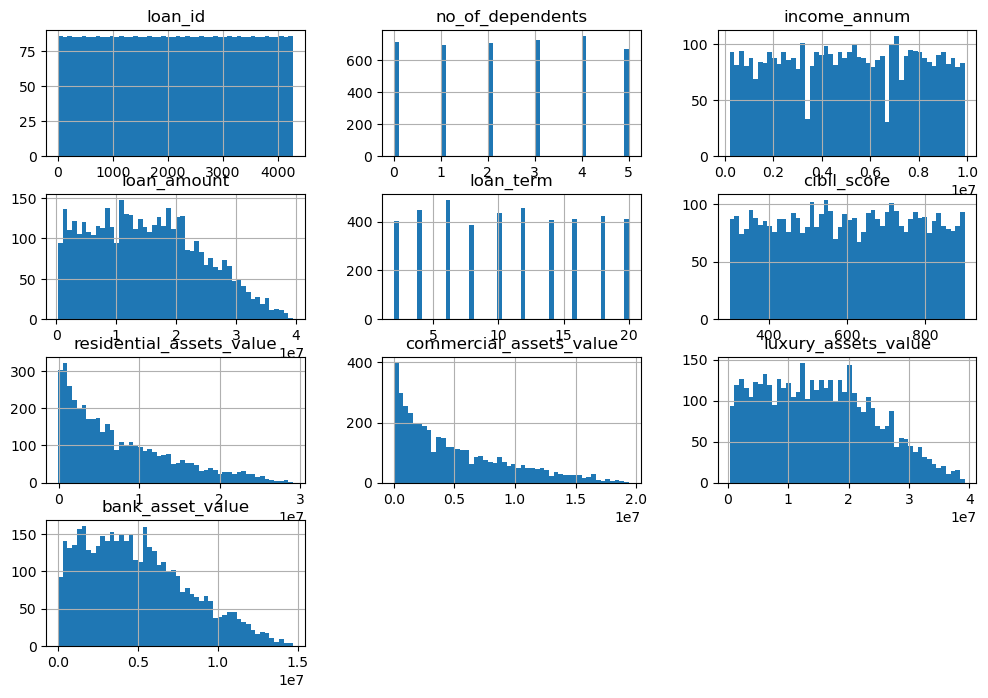

In [40]:
# drop the Loan ID column as it is not useful for prediction
df.drop('loan_id', axis=1)

df.hist(bins=50, figsize=(12, 8))


The target variable `loan_status` is either `Approved` or `Rejected`. Hence, this is a `binary classification` task.

In [41]:
#  CONVERT LABEL TO NUMERIC (BINARY)
df['loan_status'] = df['loan_status'].map({ 'Approved': 1, 'Rejected': 0 })

# .map() turns unexpected values into NaN, so fail loudly if that happens
assert df['loan_status'].notna().all(), "Unexpected value found in loan_status"

df.head(5)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


SELECT FEATURES USING CORRELATION

In [42]:
corr_matrix = df.corr(numeric_only=True)
print(corr_matrix["loan_status"].sort_values(ascending=False))

#cibil_score is the most correlated with loan_status

# checking the distribution of the target variable (loan_status)
print(df['loan_status'].value_counts())

# loan_status is imbalanced, with more approved loans than rejected loans.

loan_status                 1.000000
cibil_score                 0.770518
loan_id                     0.017685
loan_amount                 0.016150
commercial_assets_value     0.008246
bank_asset_value           -0.006778
residential_assets_value   -0.014367
income_annum               -0.015189
luxury_assets_value        -0.015465
no_of_dependents           -0.018114
loan_term                  -0.113036
Name: loan_status, dtype: float64
loan_status
1    2656
0    1613
Name: count, dtype: int64


CREATING STRATIFIED SHUFFLED SPLIT

In [43]:
from sklearn.model_selection import train_test_split

# Stratifying using loan_status to preserve equal proportion of approved and rejected loans in both training and testing sets
strat_train_set, strat_test_set = train_test_split(
    df,
    test_size=0.2,
    stratify=df["loan_status"],
    random_state=42
)

PREPROCESSING THE TRAINING DATA

In [44]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

train_set = strat_train_set.drop("loan_status", axis=1)
train_set_labels = strat_train_set["loan_status"].copy()

categorical_cols = train_set.select_dtypes(include=["object", "string"]).columns.tolist()
numerical_cols = train_set.select_dtypes(include=["int64", "float64"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

DETERMINE THE BEST CLASSIFIER ALGORITHM USING `RANDOMIZED` SEARCH

In [45]:
# Define the general cross-validation strategy
from sklearn.model_selection import StratifiedKFold

cross_validation_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

TRAIN AND EVALUATE A `LOGISTIC REGRESSION` CLASSIFIER

In [54]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from scipy.stats import loguniform

# Logistic regression is sensitive to feature scale (incomes are in the millions, cibil_score in the hundreds), so scale after preprocessing
logistic_regression_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_regression_param_distribs = {
    "classifier__C": loguniform(1e-3, 1e2),
    "classifier__class_weight": [None, "balanced"]
}

logistic_regression_search = RandomizedSearchCV(
    logistic_regression_pipeline,
    param_distributions=logistic_regression_param_distribs,
    n_iter=10,
    cv=cross_validation_strategy,
    scoring="f1", # Using F1 score for balance between precision and recall
    random_state=42
)

logistic_regression_search.fit(
    train_set,
    train_set_labels
)

# Display the best parameters:
print(logistic_regression_search.best_params_)

# Display the best F1 score achieved during the search:
print(f"Best F1 score achieved during the search: {logistic_regression_search.best_score_:.4f}")

{'classifier__C': 0.008263688714158009, 'classifier__class_weight': 'balanced'}
Best F1 score achieved during the search: 0.9330


TRAIN AND EVALUATE A `DECISION TREE CLASSIFIER`

In [47]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

decision_tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

decision_tree_param_distribs = {
    "classifier__max_depth": randint(
        low=1,
        high=10
    ),
    "classifier__min_samples_split": randint(
        low=2,
        high=12
    )
}

decision_tree_search = RandomizedSearchCV(
    estimator= decision_tree_pipeline, 
    param_distributions=decision_tree_param_distribs,
    n_iter=10,
    cv=cross_validation_strategy,
    scoring="f1", # Using F1 score for balance between precision and recall
    random_state=42,
    n_jobs=-1
)

decision_tree_search.fit(
    train_set,
    train_set_labels
)

# Display the best parameters:
print(decision_tree_search.best_params_)

# Display the best F1 score achieved during the search:
print(f"Best F1 score achieved during the search: {decision_tree_search.best_score_:.4f}")


{'classifier__max_depth': 6, 'classifier__min_samples_split': 6}
Best F1 score achieved during the search: 0.9752


TRAIN AND EVALUATE A `RANDOM FOREST CLASSIFIER`

In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint


random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

random_forest_param_distribs = {
    "classifier__n_estimators": randint(
        low=20,
        high=100
    ),
    "classifier__max_features": randint(
        low=1,
        high=10
    )
}

random_forest_search = RandomizedSearchCV(
    random_forest_pipeline,
    param_distributions=random_forest_param_distribs,
    n_iter=10,
    cv=cross_validation_strategy,
    scoring="f1", # Using F1 score for balance between precision and recall
    random_state=42
)

random_forest_search.fit(
    train_set,
    train_set_labels
)

# Display the best parameters:
print(random_forest_search.best_params_)

# Display the best F1 score achieved during the search:
print(f"Best F1 score achieved during the search: {random_forest_search.best_score_:.4f}")


{'classifier__max_features': 8, 'classifier__n_estimators': 49}
Best F1 score achieved during the search: 0.9859


EVALUATE THE `LOGISTIC-REGRESSION`, `DECISION-TREE` AND `RANDOM-FOREST` BEST ESTIMATORS ON THE TEST SET

In [59]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score

test_set = strat_test_set.drop("loan_status", axis=1)
test_set_labels = strat_test_set["loan_status"].copy()

models = {
    "Logistic Regression": logistic_regression_search.best_estimator_,
    "Decision Tree": decision_tree_search.best_estimator_,
    "Random Forest": random_forest_search.best_estimator_,
}

rows = []
for name, model in models.items():
    predictions = model.predict(test_set)
    probabilities = model.predict_proba(test_set)[:, 1]

    rows.append({
        "Model": name,
        "F1": f1_score(test_set_labels, predictions),
        "Precision": precision_score(test_set_labels, predictions),
        "Recall": recall_score(test_set_labels, predictions),
        "ROC AUC": roc_auc_score(test_set_labels, probabilities),
    })

model_comparison = pd.DataFrame(rows)
model_comparison

,Model,F1,Precision,Recall,ROC AUC
0,Logistic Regression,0.944606,0.975904,0.915254,0.973839
1,Decision Tree,0.979667,0.961887,0.998117,0.992371
2,Random Forest,0.991565,0.986940,0.996234,0.997338


PLOT THE CONFUSION MATRICES

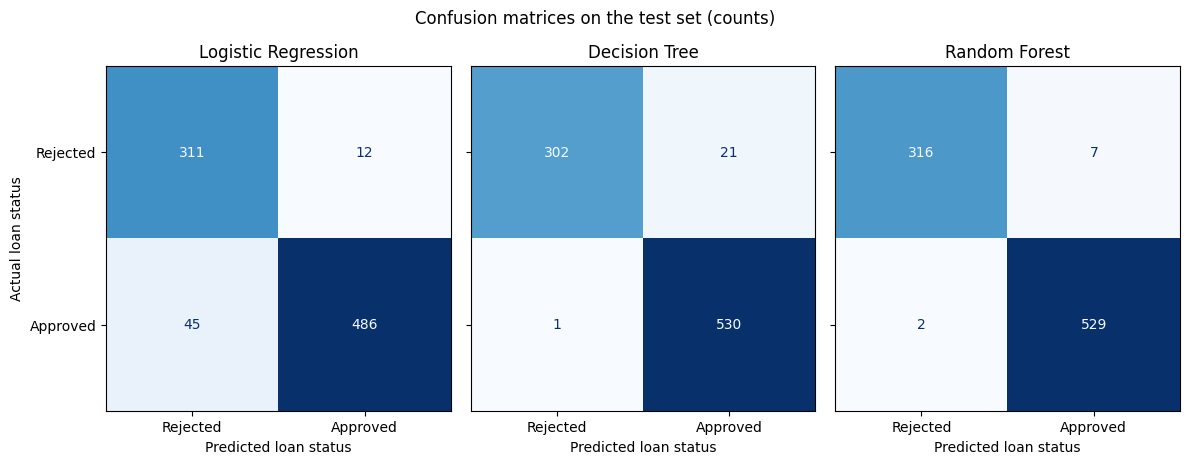

In [61]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# One panel per model (each panel has its own colour scale; read the counts in the cells)
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4.5), sharey=True)

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        test_set_labels,
        model.predict(test_set),
        display_labels=["Rejected", "Approved"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted loan status")
    ax.set_ylabel("Actual loan status" if ax is axes[0] else "")
    ax.grid(False)

fig.suptitle("Confusion matrices on the test set (counts)")
fig.tight_layout()
plt.show()